In [2]:
pip -q install gr

Entorno listo · scikit-learn: 1.6.1
Registros cargados: 1338 | Columnas: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'fumador_obeso']
Costo medio fumadores:    $32.050.232
Costo medio no fumadores: $8.434.268

Modelo Regresor seleccionado: Gradient Boosting (ajustado) | R2 Test: 0.879 | MAE Test: $2.456.852
Silhouette Score K-Means (k=3): 0.2044
Random Forest Clasificador -> Accuracy CV: 0.967 | Accuracy Test: 0.966 | F1 Macro: 0.963

Reporte de Clasificación (Test):
               precision    recall  f1-score   support

 Riesgo Alto       1.00      0.91      0.95        33
 Riesgo Bajo       0.98      0.97      0.97       117
Riesgo Medio       0.94      0.98      0.96       118

    accuracy                           0.97       268
   macro avg       0.98      0.95      0.96       268
weighted avg       0.97      0.97      0.97       268


Perfil de Segmentos:
              afiliados  edad_media  imc_medio  pct_fumadores  costo_esperado  \
segmento              

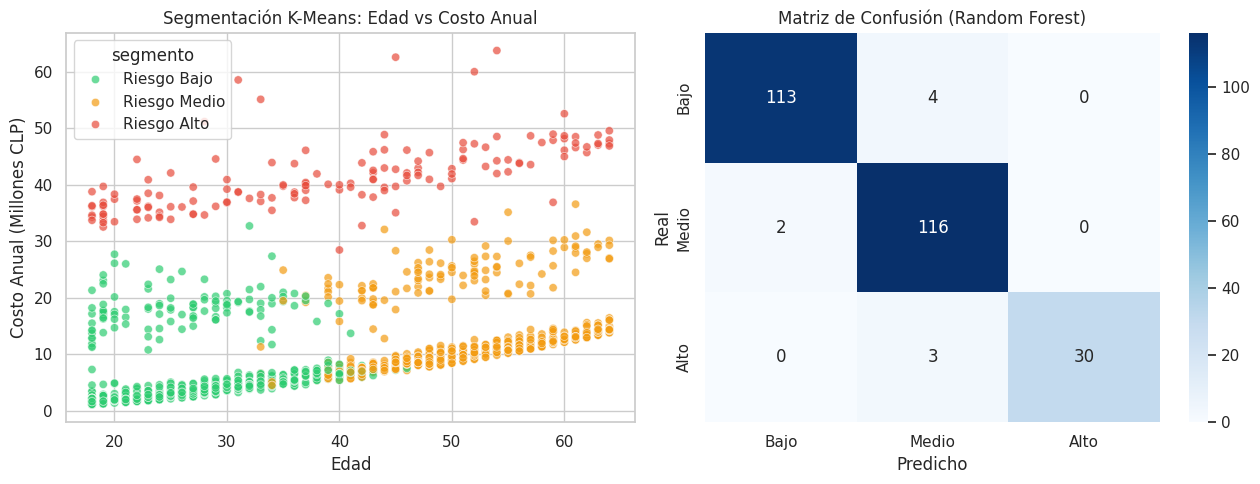


TABLERO EJECUTIVO
  Afiliados en riesgo alto: 11% | Costo esperado promedio: $39.990.432
  Error promedio (MAE): $2.456.852 | Estado semáforo (mes 12): ROJO
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6dce6101d6b2259fc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [3]:
# ==============================================================================
# SALUD VITAL S.A. · ESTIMACIÓN DE COSTOS, SEGMENTACIÓN (K-MEANS) Y CLASIFICACIÓN (RF)
# ==============================================================================

import warnings, json, hashlib, os, io, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, joblib
import gradio as gr

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score, accuracy_score, f1_score, classification_report, confusion_matrix
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

def clp(x):
    return "$" + f"{x:,.0f}".replace(",", ".")

print("Entorno listo · scikit-learn:", sklearn.__version__)

# ==============================================================================
# 1. DATOS · Carga, validación y calidad
# ==============================================================================
URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

def cargar_datos():
    if os.path.exists("insurance.csv"):
        return pd.read_csv("insurance.csv")
    try:
        from google.colab import files
        print("Sube insurance.csv (o cancela para descargarlo automáticamente)")
        subido = files.upload()
        if subido:
            return pd.read_csv(io.BytesIO(next(iter(subido.values()))))
    except ImportError:
        pass
    return pd.read_csv(URL)

df = cargar_datos()

# Escalar a CLP (x1000) si el dataset viene en USD
ESCALA_CLP = 1000
if df["charges"].mean() < 100_000:
    df["charges"] = df["charges"] * ESCALA_CLP

# Variable derivada clínica (interacción fumar + obesidad)
df["fumador_obeso"] = ((df["smoker"] == "yes") & (df["bmi"] >= 30)).astype(int)

print(f"Registros cargados: {len(df)} | Columnas: {list(df.columns)}")
print("Costo medio fumadores:   ", clp(df.loc[df.smoker == "yes", "charges"].mean()))
print("Costo medio no fumadores:", clp(df.loc[df.smoker == "no", "charges"].mean()))

# ==============================================================================
# 2. MODELO DE REGRESIÓN · Estimación del Costo Médico Anual
# ==============================================================================
NUM = ["age", "bmi", "children"]
CAT = ["sex", "smoker", "region"]
FEATURES = NUM + CAT + ["fumador_obeso"]
TARGET = "charges"

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=df["smoker"]
)

trazabilidad = {
    "hash_dataset_md5": hashlib.md5(pd.util.hash_pandas_object(df[FEATURES + [TARGET]]).values.tobytes()).hexdigest(),
    "semilla": SEED,
    "n_train": len(X_train),
    "n_test": len(X_test),
    "python": platform.python_version(),
    "sklearn": sklearn.__version__,
    "pandas": pd.__version__,
}

pre = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first"), CAT),
], remainder="passthrough")

def pipe(modelo_reg):
    return Pipeline([("pre", pre), ("modelo", modelo_reg)])

candidatos = {
    "Regresión lineal":  pipe(LinearRegression()),
    "Ridge":             pipe(Ridge(alpha=1.0)),
    "Random Forest":     pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting": pipe(GradientBoostingRegressor(random_state=SEED)),
}

grid = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [2, 3],
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__min_samples_leaf": [10, 20],
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
gs = GridSearchCV(
    pipe(GradientBoostingRegressor(random_state=SEED)),
    grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
)
gs.fit(X_train, y_train)
candidatos["Gradient Boosting (ajustado)"] = gs.best_estimator_

filas = []
for nombre, m in candidatos.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=("neg_root_mean_squared_error", "r2"))
    filas.append({
        "modelo": nombre,
        "RMSE_cv": -r["test_neg_root_mean_squared_error"].mean(),
        "R2_cv": r["test_r2"].mean(),
    })

comparacion = pd.DataFrame(filas).sort_values("RMSE_cv").reset_index(drop=True)
mejor = comparacion.loc[0, "modelo"]
modelo = candidatos[mejor].fit(X_train, y_train)

pred_te = modelo.predict(X_test)
R2_BASE = r2_score(y_test, pred_te)
MAE_BASE = mean_absolute_error(y_test, pred_te)
print(f"\nModelo Regresor seleccionado: {mejor} | R2 Test: {R2_BASE:.3f} | MAE Test: {clp(MAE_BASE)}")

# ==============================================================================
# 3. SEGMENTACIÓN (K-MEANS) Y CLASIFICACIÓN (RANDOM FOREST)
# ==============================================================================
# 3.1 K-Means (usando variables clínicas, demográficas y costo real)
NUM_SEG = ["age", "bmi", "children", "charges"]
CAT_SEG = ["sex", "smoker", "region"]

pre_seg = ColumnTransformer([
    ("num", StandardScaler(), NUM_SEG),
    ("cat", OneHotEncoder(drop="first"), CAT_SEG)
], remainder="passthrough")

X_seg = pre_seg.fit_transform(df[NUM_SEG + CAT_SEG + ["fumador_obeso"]])

kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
df["cluster_id"] = kmeans.fit_predict(X_seg)

# Etiquetar automáticamente de menor a mayor costo medio
orden_clusters = df.groupby("cluster_id")["charges"].mean().sort_values().index
mapa_segmentos = {
    orden_clusters[0]: "Riesgo Bajo",
    orden_clusters[1]: "Riesgo Medio",
    orden_clusters[2]: "Riesgo Alto"
}
df["segmento"] = df["cluster_id"].map(mapa_segmentos)
print(f"Silhouette Score K-Means (k=3): {silhouette_score(X_seg, df['cluster_id']):.4f}")

# 3.2 Random Forest Classifier (predice segmento sin usar 'charges')
y_seg_train = df.loc[X_train.index, "segmento"]
y_seg_test  = df.loc[X_test.index, "segmento"]

clasificador_rf = Pipeline([
    ("pre", pre),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        random_state=SEED,
        n_jobs=-1
    ))
])

cv_acc_seg = cross_val_score(clasificador_rf, X_train, y_seg_train, cv=5, scoring="accuracy")
clasificador_rf.fit(X_train, y_seg_train)
pred_seg_test = clasificador_rf.predict(X_test)

ACC_SEG = accuracy_score(y_seg_test, pred_seg_test)
F1_SEG  = f1_score(y_seg_test, pred_seg_test, average="macro")
print(f"Random Forest Clasificador -> Accuracy CV: {cv_acc_seg.mean():.3f} | Accuracy Test: {ACC_SEG:.3f} | F1 Macro: {F1_SEG:.3f}")
print("\nReporte de Clasificación (Test):\n", classification_report(y_seg_test, pred_seg_test))

# Resumen de perfiles por segmento
seg = df.copy()
seg["costo_esperado"] = modelo.predict(df[FEATURES])

perfil = seg.groupby("segmento").agg(
    afiliados=("age", "size"),
    edad_media=("age", "mean"),
    imc_medio=("bmi", "mean"),
    pct_fumadores=("smoker", lambda s: (s == "yes").mean() * 100),
    costo_esperado=("costo_esperado", "mean"),
    costo_real=("charges", "mean"),
).reindex(["Riesgo Bajo", "Riesgo Medio", "Riesgo Alto"]).round(1)

print("\nPerfil de Segmentos:")
print(perfil)

# Gráficos de Segmentación y Matriz de Confusión
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(
    data=df, x="age", y=df["charges"] / 1e6,
    hue="segmento", hue_order=["Riesgo Bajo", "Riesgo Medio", "Riesgo Alto"],
    palette=["#2ecc71", "#f39c12", "#e74c3c"], alpha=0.7, ax=ax[0]
)
ax[0].set(title="Segmentación K-Means: Edad vs Costo Anual", xlabel="Edad", ylabel="Costo Anual (Millones CLP)")

cm = confusion_matrix(y_seg_test, pred_seg_test, labels=["Riesgo Bajo", "Riesgo Medio", "Riesgo Alto"])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Bajo", "Medio", "Alto"],
    yticklabels=["Bajo", "Medio", "Alto"], ax=ax[1]
)
ax[1].set(title="Matriz de Confusión (Random Forest)", xlabel="Predicho", ylabel="Real")
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. OPERACIÓN · Monitoreo con semáforo (PSI + R2 mensual)
# ==============================================================================
def psi(ref, new, bins=5):
    ref, new = np.asarray(ref, float), np.asarray(new, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p = np.histogram(ref, edges)[0] / len(ref) + 1e-4
    q = np.histogram(new, edges)[0] / len(new) + 1e-4
    return float(np.sum((q - p) * np.log(q / p)))

def psi_binaria(ref, new):
    p = np.array([1 - ref.mean(), ref.mean()]) + 1e-4
    q = np.array([1 - new.mean(), new.mean()]) + 1e-4
    return float(np.sum((q - p) * np.log(q / p)))

U_R2 = {"amarillo": 0.70, "rojo": 0.60}
U_PSI = {"amarillo": 0.10, "rojo": 0.25}
def color_r2(v):  return "ROJO" if v < U_R2["rojo"] else ("AMARILLO" if v < U_R2["amarillo"] else "VERDE")
def color_psi(v): return "ROJO" if v >= U_PSI["rojo"] else ("AMARILLO" if v >= U_PSI["amarillo"] else "VERDE")
ORDEN = {"VERDE": 0, "AMARILLO": 1, "ROJO": 2}

rng = np.random.default_rng(SEED)
pool = X_test.copy()
pool["real"] = y_test.values
registros = []

for mes in range(1, 13):
    w = np.ones(len(pool))
    if mes >= 5:
        k = 0.5 * (mes - 4)
        w = 1 + k * (pool.bmi >= 30).values + k * (pool.smoker == "yes").values
    muestra = pool.sample(300, replace=True, weights=w, random_state=int(rng.integers(1e9))).copy()
    if mes >= 8:
        muestra["real"] = muestra["real"] * (1 + 0.15 * (mes - 7))
    p = modelo.predict(muestra[FEATURES])
    r2m = r2_score(muestra.real, p)
    psi_max = max(
        psi(X_train.bmi, muestra.bmi),
        psi(X_train.age, muestra.age),
        psi_binaria((X_train.smoker == "yes").astype(int), (muestra.smoker == "yes").astype(int))
    )
    c_r2, c_psi = color_r2(r2m), color_psi(psi_max)
    estado = max([c_r2, c_psi], key=ORDEN.get)
    registros.append({"mes": mes, "R2": r2m, "PSI_max": psi_max, "estado": estado})

monitoreo = pd.DataFrame(registros)
ultimo = monitoreo.iloc[-1]
alto = (seg.segmento == "Riesgo Alto").mean() * 100

print("\nTABLERO EJECUTIVO")
print(f"  Afiliados en riesgo alto: {alto:.0f}% | Costo esperado promedio: {clp(perfil.loc['Riesgo Alto', 'costo_esperado'])}")
print(f"  Error promedio (MAE): {clp(MAE_BASE)} | Estado semáforo (mes {int(ultimo.mes)}): {ultimo.estado}")

# ==============================================================================
# 5. DESPLIEGUE · Guardar artefactos y lanzar App Web en Gradio
# ==============================================================================
os.makedirs("artefactos", exist_ok=True)
joblib.dump(modelo, "artefactos/modelo_costos.joblib")
joblib.dump(clasificador_rf, "artefactos/clasificador_segmento.joblib")

metadatos = {
    "modelo_regresion": mejor,
    "modelo_clasificacion": "RandomForestClassifier (sobre clusters K-Means k=3)",
    "features": FEATURES,
    "R2_prueba": float(R2_BASE),
    "MAE_prueba": float(MAE_BASE),
    "Accuracy_segmento": float(ACC_SEG),
    "F1_segmento": float(F1_SEG),
    "trazabilidad": trazabilidad
}
with open("artefactos/metadatos.json", "w") as f:
    json.dump(metadatos, f, indent=2)

modelo_app = joblib.load("artefactos/modelo_costos.joblib")
clf_app    = joblib.load("artefactos/clasificador_segmento.joblib")

def estimar_y_clasificar(edad, sexo, imc, hijos, fumador, region):
    fila = pd.DataFrame([{
        "age": edad,
        "sex": sexo,
        "bmi": imc,
        "children": hijos,
        "smoker": fumador,
        "region": region,
        "fumador_obeso": int(fumador == "yes" and imc >= 30)
    }])[FEATURES]

    costo = float(modelo_app.predict(fila)[0])
    segmento_pred = clf_app.predict(fila)[0]
    probs = clf_app.predict_proba(fila)[0]

    orden_etiquetas = ["Riesgo Bajo", "Riesgo Medio", "Riesgo Alto"]
    mapa_probs = dict(zip(clf_app.classes_, probs))
    probabilidades_dict = {etq: float(mapa_probs.get(etq, 0.0)) for etq in orden_etiquetas}

    nota = (
        f"Perfil asignado a '{segmento_pred}' con {probabilidades_dict[segmento_pred]*100:.1f}% de confianza. "
        "Herramienta de apoyo actuarial: toda recalificación tarifaria requiere revisión del comité técnico."
    )
    return clp(costo), probabilidades_dict, nota

app = gr.Interface(
    fn=estimar_y_clasificar,
    inputs=[
        gr.Slider(18, 64, value=35, step=1, label="Edad"),
        gr.Radio([("Hombre", "male"), ("Mujer", "female")], value="female", label="Sexo"),
        gr.Slider(15, 55, value=27, step=0.1, label="IMC"),
        gr.Slider(0, 5, value=1, step=1, label="Número de hijos"),
        gr.Radio([("No", "no"), ("Sí", "yes")], value="no", label="¿Fuma?"),
        gr.Dropdown(["northeast", "northwest", "southeast", "southwest"], value="southeast", label="Región")
    ],
    outputs=[
        gr.Textbox(label="Costo médico anual esperado (CLP)"),
        gr.Label(num_top_classes=3, label="Segmento de Riesgo (Probabilidad Random Forest)"),
        gr.Textbox(label="Nota de apoyo actuarial")
    ],
    title="Salud Vital S.A. · Estimador de Costo y Segmentación de Riesgo",
    description="Combina Regresión para estimación monetaria y K-Means + Random Forest para clasificación de perfil de riesgo.",
    flagging_mode="never",
)

if __name__ == "__main__":
    app.launch(share=True)